
 Random Forest
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



c:\Users\Ghanavi Arun\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(



 AdaBoost
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


MODEL PERFORMANCE COMPARISON
        Model  Accuracy  Precision  Recall  F1 Score  Specificity  ROC-AUC  Training Time
Random Forest    0.9561     0.9589  0.9722    0.9655       0.9286   0.9937         0.1467
     AdaBoost    0.9561     0.9467  0.9861    0.9660       0.9048   0.9805         0.2391


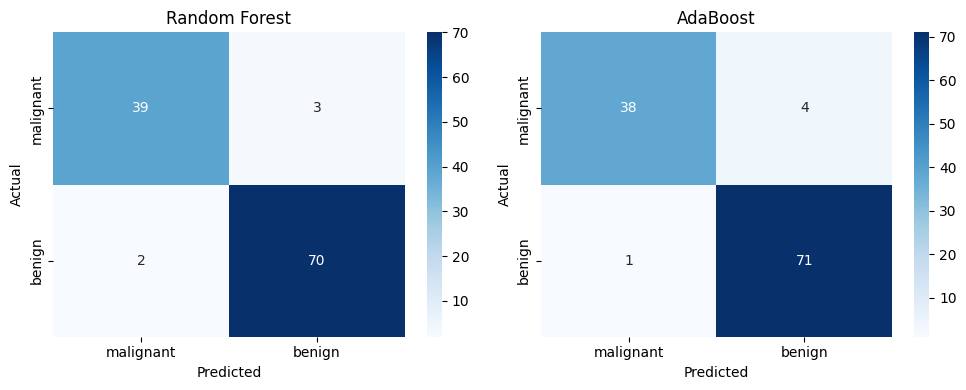

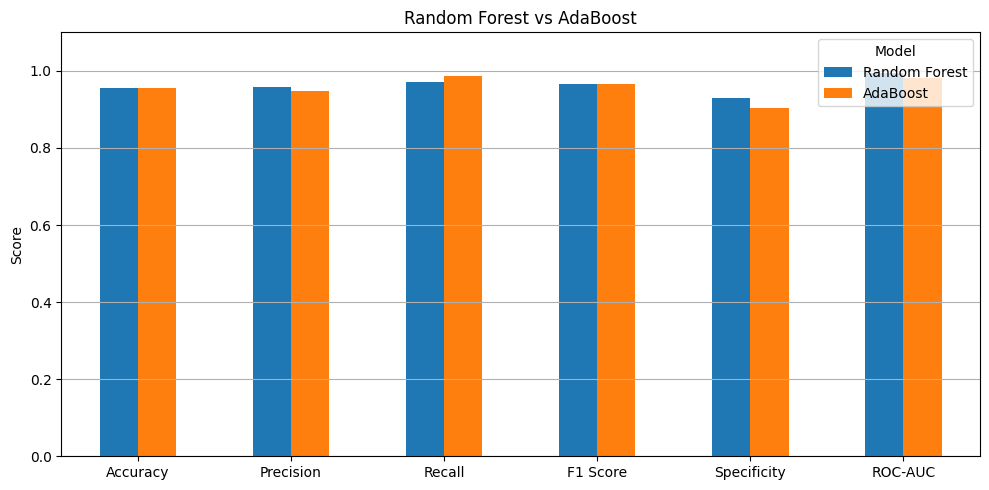

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# ---------------------------------------
# 1. CREATE MODELS
# ---------------------------------------

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    )
}


# ---------------------------------------
# 2. TRAIN AND EVALUATE
# ---------------------------------------

results = []
confusion_matrices = {}

for name, model in models.items():

    start = time.time()

    model.fit(X_train, y_train)

    training_time = time.time() - start

    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    confusion_matrices[name] = cm

    # Classification metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "Specificity": tn / (tn + fp),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Training Time": training_time
    })

    print("\n", name)
    print(classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    ))


# ---------------------------------------
# 3. COMPARE ALL METRICS
# ---------------------------------------

results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
print(results_df.round(4).to_string(index=False))


# ---------------------------------------
# 4. CONFUSION MATRICES
# ---------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, cm) in zip(axes, confusion_matrices.items()):

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=data.target_names,
        yticklabels=data.target_names
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


# ---------------------------------------
# 5. COMPARE CLASSIFICATION METRICS
# ---------------------------------------

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "Specificity",
    "ROC-AUC"
]

results_df.set_index("Model")[metrics].T.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Random Forest vs AdaBoost")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.grid(axis="y")
plt.tight_layout()
plt.show()